In [1]:
# CISC7204 Practice 07: Draw Me a Visualization

# 1. Data Loading and Preprocessing
#This section loads the dataset, merges red and white wines, and handles outliers to ensure a clean visualization.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.lines as mlines

# Set visual style for academic presentation
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.size'] = 11

# Load datasets (using UCI URLs)
red_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
white_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"

red = pd.read_csv(red_url, sep=";")
white = pd.read_csv(white_url, sep=";")

# Add wine_type label to distinguish red and white wines
red["wine_type"] = "red"
white["wine_type"] = "white"

# Merge into a single DataFrame
wines = pd.concat([red, white], ignore_index=True)

# Data cleaning: filter out extreme volatile acidity outliers (>1.2) 
# to prevent the Y-axis from being stretched too far, which would compress the main data cluster.
wines_clean = wines[wines["volatile acidity"] < 1.2].copy()

print(f"Original dataset shape: {wines.shape}")
print(f"Cleaned dataset shape: {wines_clean.shape}")

Original dataset shape: (6497, 13)
Cleaned dataset shape: (6493, 13)


In [ ]:
# 2. Data Exploration and Insight Discovery
#The goal is to identify the relationship between chemical properties and wine quality.

In [2]:
# Check the distribution of wine quality scores
print(wines_clean["quality"].value_counts().sort_index())

# Calculate correlation between continuous variables and quality
numeric_cols = wines_clean.select_dtypes(include=np.number).columns
corr_matrix = wines_clean[numeric_cols].corr()
print("\nTop correlations with 'quality':")
print(corr_matrix["quality"].sort_values(ascending=False))

quality
3      29
4     216
5    2135
6    2836
7    1079
8     193
9       5
Name: count, dtype: int64

Top correlations with 'quality':
quality                 1.000000
alcohol                 0.444950
citric acid             0.084008
free sulfur dioxide     0.054396
sulphates               0.037997
pH                      0.020922
residual sugar         -0.037703
total sulfur dioxide   -0.042842
fixed acidity          -0.076206
chlorides              -0.199518
volatile acidity       -0.262930
density                -0.305876
Name: quality, dtype: float64


In [3]:
# 3. Visualization: Alcohol vs Volatile Acidity
#Based on the correlation analysis, `alcohol` and `volatile acidity` show the strongest positive and negative correlations with `quality`, respectively. 
#A 2D scatter plot is chosen to display the joint distribution of these two continuous variables, using color and shape for multidimensional encoding.

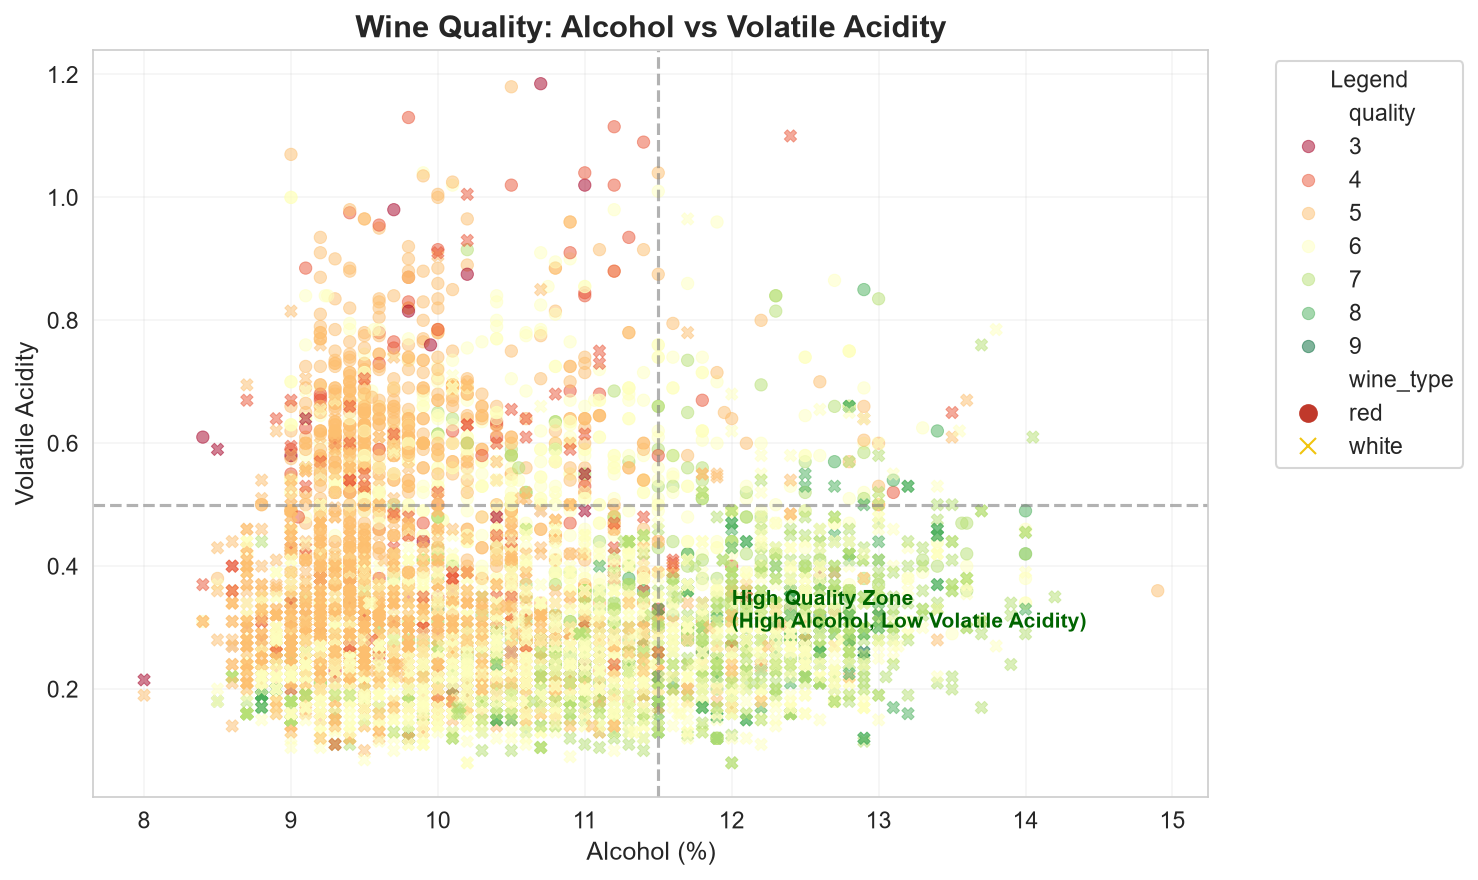

In [4]:
plt.figure(figsize=(10, 6))

# 1. Plot the scatter plot
ax = sns.scatterplot(
    data=wines_clean,
    x="alcohol",
    y="volatile acidity",
    hue="quality",          # Color encodes quality (Red = low, Green = high)
    style="wine_type",      # Shape distinguishes red and white wines
    palette="RdYlGn",       # Red-Yellow-Green diverging palette
    alpha=0.5,              # Transparency reveals data density
    s=35,                   # Point size
    edgecolor=None          # Remove edge lines for cleaner look
)

# 2. Fix legend colors to intuitively match wine types (Red and White)
handles, labels = ax.get_legend_handles_labels()
new_handles = []
for h, l in zip(handles, labels):
    if l == "red":
        new_handles.append(mlines.Line2D([], [], color="#C0392B", marker='o', linestyle='None', markersize=8))
    elif l == "white":
        new_handles.append(mlines.Line2D([], [], color="#F1C40F", marker='x', linestyle='None', markersize=8))
    else:
        new_handles.append(h)

ax.legend(new_handles, labels, bbox_to_anchor=(1.05, 1), loc='upper left', title="Legend")

# 3. Add reference lines and annotations for the "High Quality Zone"
plt.axvline(x=11.5, color="gray", linestyle="--", alpha=0.6)
plt.axhline(y=0.5, color="gray", linestyle="--", alpha=0.6)
plt.text(12, 0.3, "High Quality Zone\n(High Alcohol, Low Volatile Acidity)", 
         fontsize=10, color="darkgreen", fontweight="bold")

# 4. Final Aesthetic Touches
plt.title("Wine Quality: Alcohol vs Volatile Acidity", fontsize=15, fontweight="bold")
plt.xlabel("Alcohol (%)", fontsize=12)
plt.ylabel("Volatile Acidity", fontsize=12)
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()

In [5]:
# 4. Conclusion
#The visualization clearly demonstrates that high-quality wines (green points) tend to cluster in the bottom-right quadrant, characterized by high alcohol content and low volatile acidity. Red and white wines exhibit distinct distribution patterns, with red wines generally having higher volatile acidity.

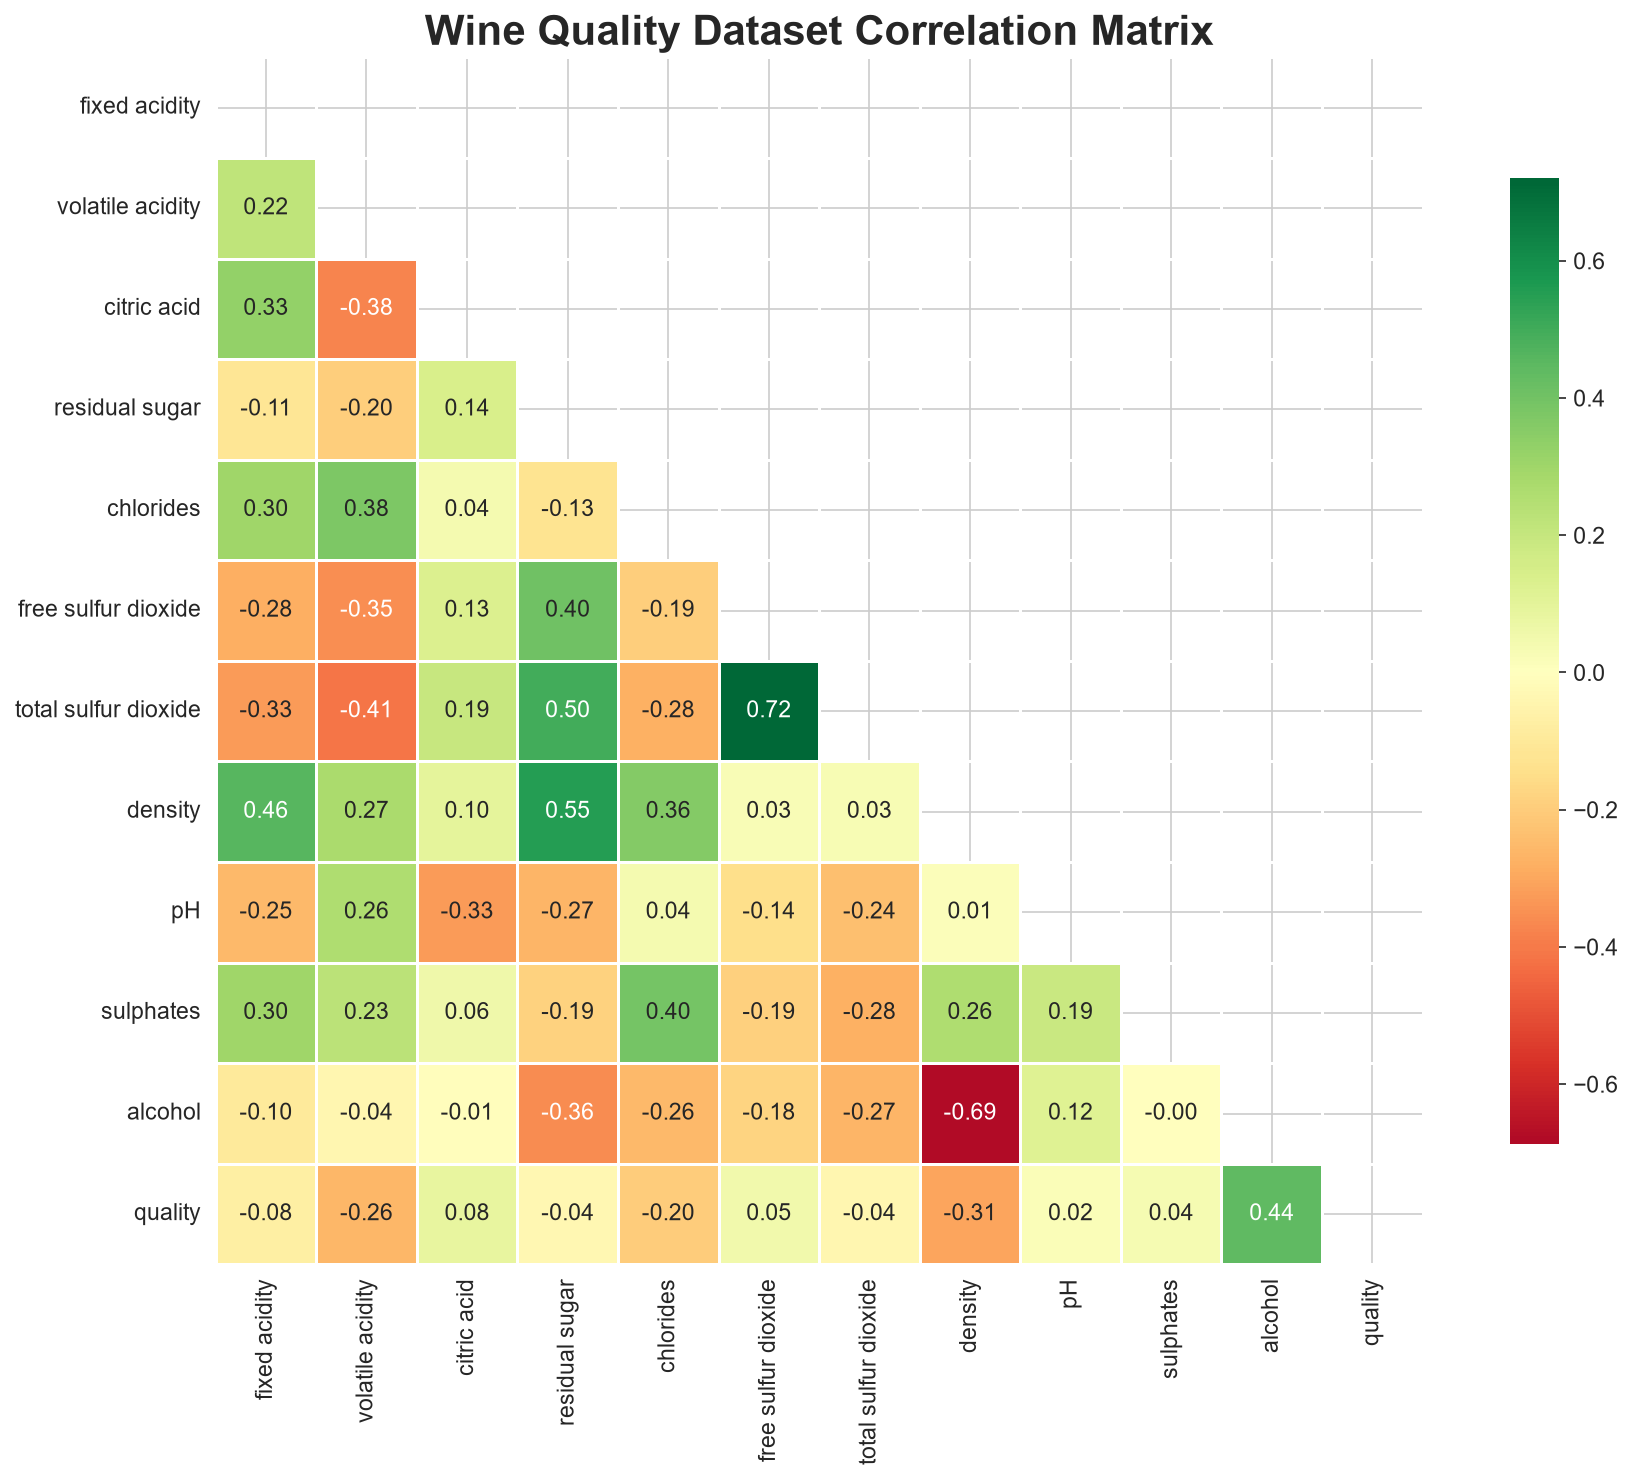

In [7]:
plt.figure(figsize=(13, 10))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdYlGn",
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Wine Quality Dataset Correlation Matrix", fontsize=20, weight="bold")
plt.tight_layout()
plt.savefig("visualization2.png", dpi=300, bbox_inches="tight")
plt.show()